# Motion acquisition

In [3]:
import numpy as np
import parallelproj.pet_scanners
import parallelproj.pet_lors
import parallelproj.projectors
import matplotlib.pyplot as plt
from parallelproj._examples_utils import show_vol_cuts

In [4]:
from parallelproj._examples_utils import suggest_array_backend_and_device
print(parallelproj.__version__)
# To use a specific backend and/or device, replace the None arguments, e.g.:
#   xp, dev = suggest_array_backend_and_device(backend="numpy", dev="cpu") or by setting xp and dev manually
xp, dev = suggest_array_backend_and_device(None, None)

2.0.2
Using array API: array_api_compat.numpy, device: cpu


In [5]:
scanner1 = parallelproj.pet_scanners.RegularPolygonPETScannerGeometry(
    xp,
    dev,
    radius=100.0,#65.0,
    num_sides=12,
    num_lor_endpoints_per_side=35,
    lor_spacing=1.27,
    #ring_positions=xp.linspace(-17.5, 17.5, 3, device=dev),
    ring_positions=xp.linspace(0, 35*1.27, 35, device=dev),
    symmetry_axis=2,
)

In [6]:
print("scanner1")
print(
    scanner1.get_lor_endpoints(
        xp.asarray([0, 1], device=dev), xp.asarray([3, 4], device=dev)
    )
)

scanner1
[[ -17.779999  -100.           0.       ]
 [ -16.51      -100.           1.3073529]]


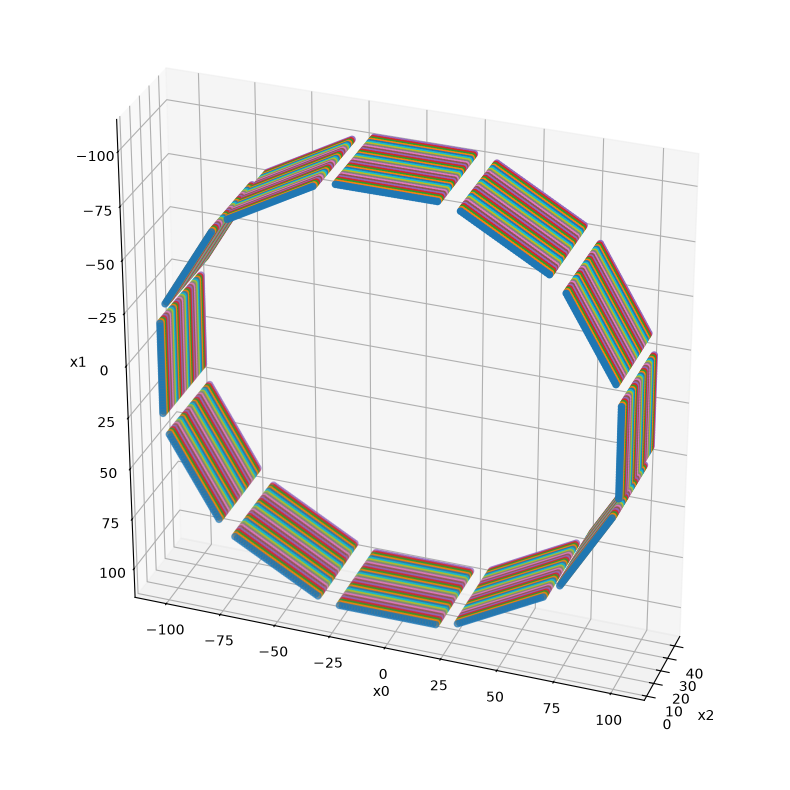

In [7]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection="3d")

ax.view_init(elev=-30, azim=160, roll=180, vertical_axis="y")
scanner1.show_lor_endpoints(ax)

plt.tight_layout()
plt.show()

In [8]:
lor_desc = parallelproj.pet_lors.RegularPolygonPETLORDescriptor(
    scanner1,
    parallelproj.pet_lors.Michelogram(scanner1.num_rings, max_ring_difference=2, span=1),
    radial_trim=10,
    sinogram_order=parallelproj.pet_lors.SinogramSpatialAxisOrder.RVP,
)

In [38]:
proj = parallelproj.projectors.RegularPolygonPETProjector(
    lor_desc,
    img_shape=(100, 100, 20),
    voxel_size=(1.0, 1.0, 1.0),
    img_origin=(-50, -50, 10),
)

C:\Users\katel\AppData\Local\Temp\ipykernel_14640\1358941737.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


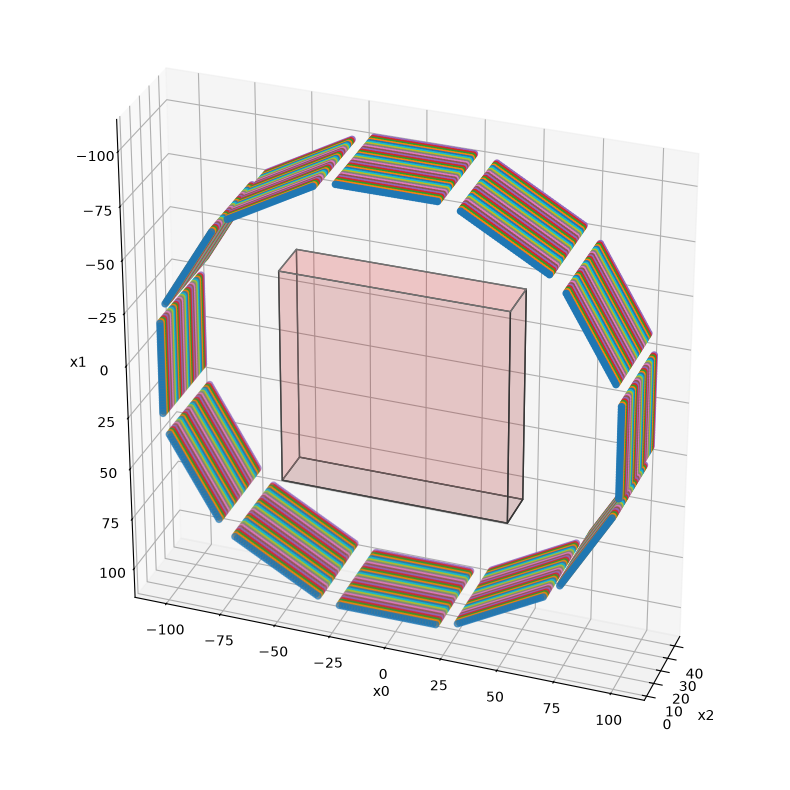

In [39]:
fig = plt.figure(figsize=(16, 8))
ax1 = fig.add_subplot(111, projection="3d")
ax1.view_init(elev=-30, azim=160, roll=180, vertical_axis="y")
proj.show_geometry(ax1)
fig.tight_layout()
fig.show()

100 100 20


C:\Users\katel\AppData\Local\Temp\ipykernel_14640\1455841018.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\katel\AppData\Local\Temp\ipykernel_14640\1455841018.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig2.show()
C:\Users\katel\AppData\Local\Temp\ipykernel_14640\1455841018.py:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig3.show()
C:\Users\katel\AppData\Local\Temp\ipykernel_14640\1455841018.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig4.show()


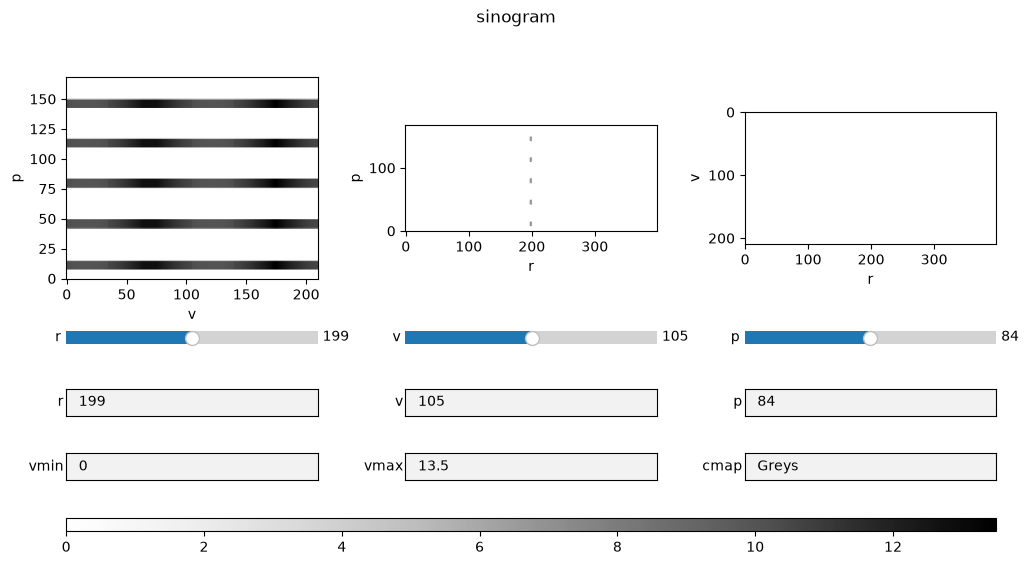

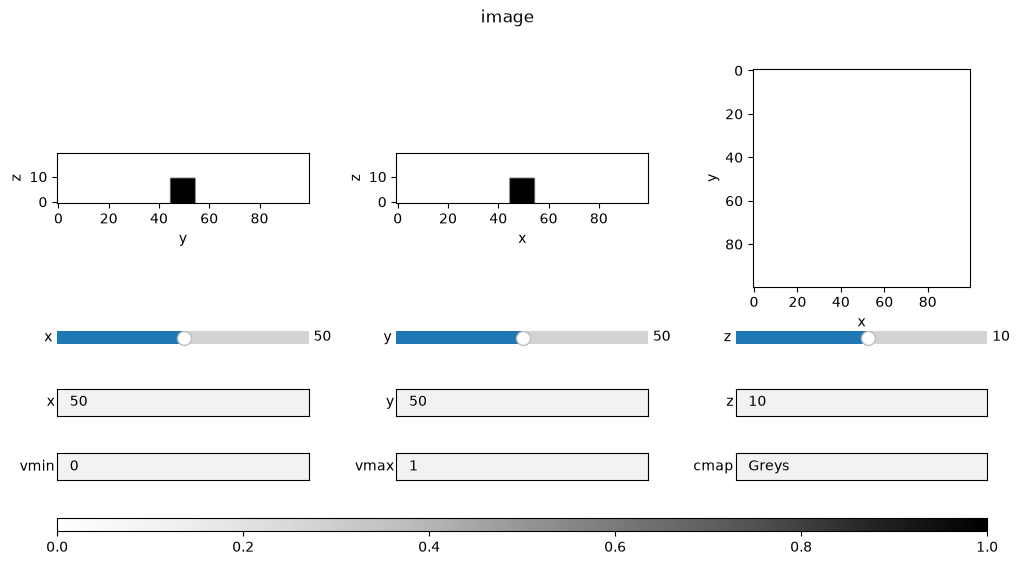

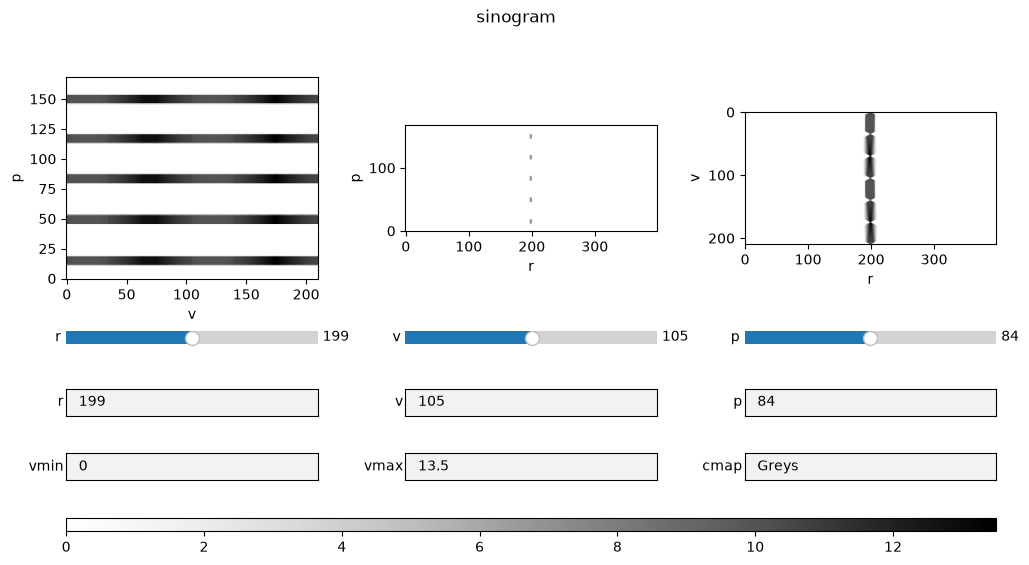

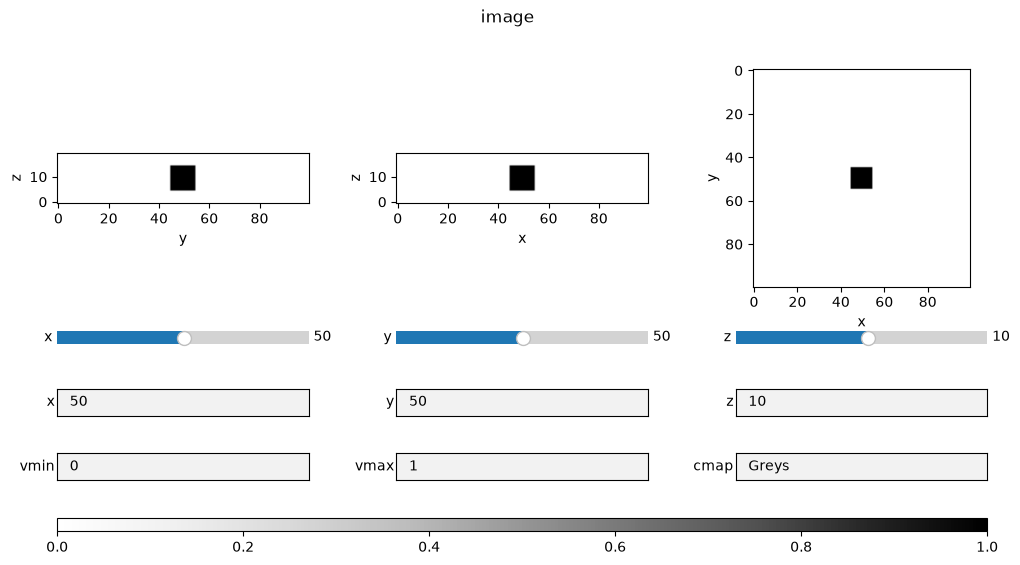

In [43]:
n=3
d,h,w=proj.in_shape
c=np.linspace(5,15,n).astype('int')
print(d,h,w)
image=[]
sino=[]
back=[]
for i in range(n):
    x = xp.zeros(proj.in_shape, device=dev, dtype=xp.float32)
    x[45:55, 45:55, c[i]-5:c[i]+5] = 1.0
    image.append(x)
    x_fwd = proj(x)
    sino.append(x_fwd)
    x_fwd_back = proj.adjoint(x_fwd)
    back.append(x_fwd_back)

# visualize the forward projection
fig, _, widgets = show_vol_cuts(
    sino[0], axis_labels=("r", "v", "p"), fig_title="sinogram"
)
fig.savefig("sinogram 1")
fig.show()

# visualize the image
fig2, _, widgets2 = show_vol_cuts(image[0], fig_title="image")
fig2.savefig("image 1")
fig2.show()

# visualize the forward projection
fig3, _, widgets3 = show_vol_cuts(
    sino[1], axis_labels=("r", "v", "p"), fig_title="sinogram"
)
fig3.savefig("sinogram 2")
fig3.show()

# visualize the image
fig4, _, widgets4 = show_vol_cuts(image[1], fig_title="image")
fig4.savefig("image 2")
fig4.show()

C:\Users\katel\AppData\Local\Temp\ipykernel_14640\1769920553.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\katel\AppData\Local\Temp\ipykernel_14640\1769920553.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig2.show()


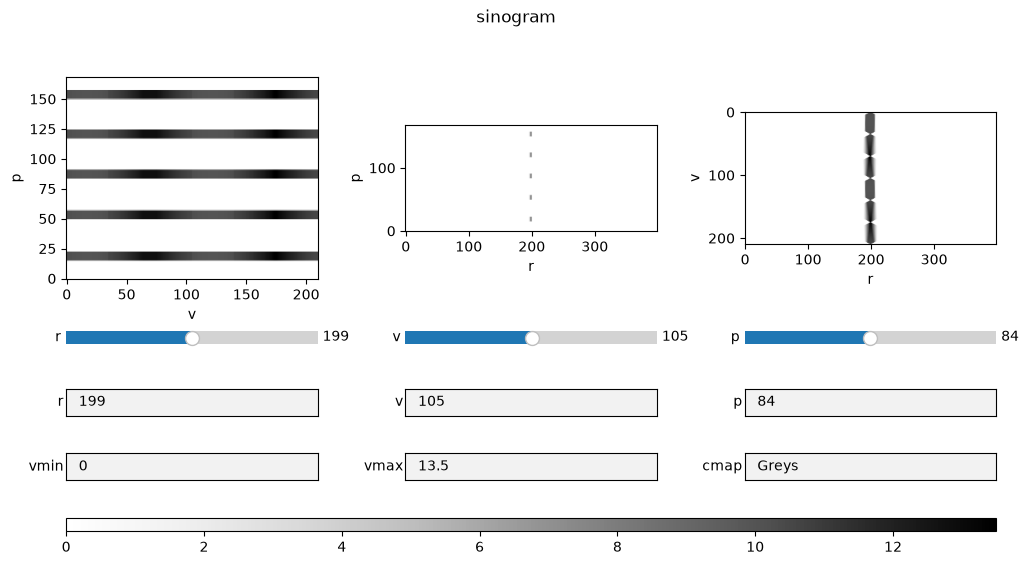

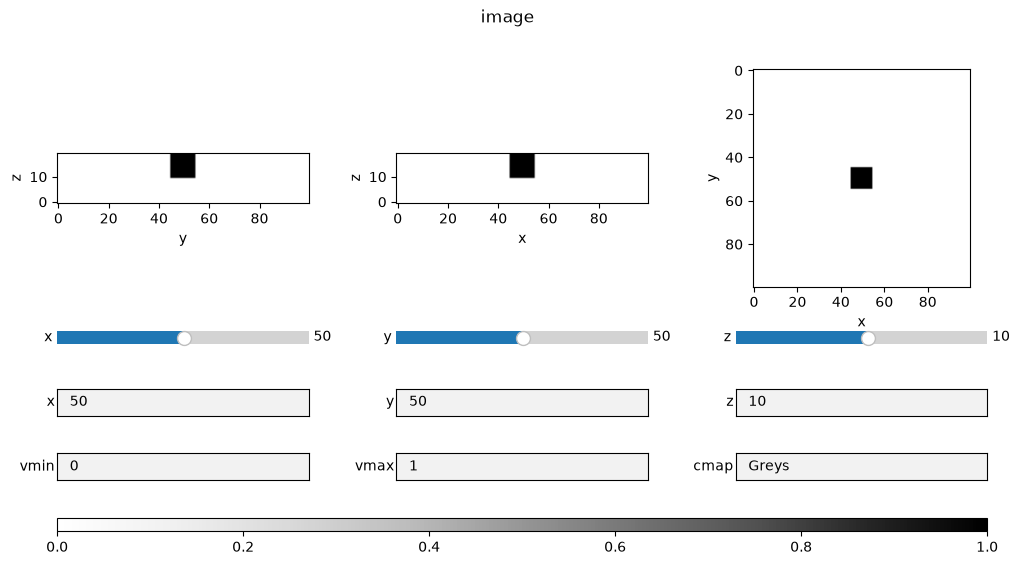

In [41]:
# visualize the forward projection
fig, _, widgets = show_vol_cuts(
    sino[2], axis_labels=("r", "v", "p"), fig_title="sinogram"
)
fig.savefig("sinogram 3")
fig.show()

# visualize the image
fig2, _, widgets2 = show_vol_cuts(image[2], fig_title="image")
fig2.savefig("image 3")
fig2.show()

C:\Users\katel\AppData\Local\Temp\ipykernel_14640\2101538118.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\katel\AppData\Local\Temp\ipykernel_14640\2101538118.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig2.show()
C:\Users\katel\AppData\Local\Temp\ipykernel_14640\2101538118.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig3.show()


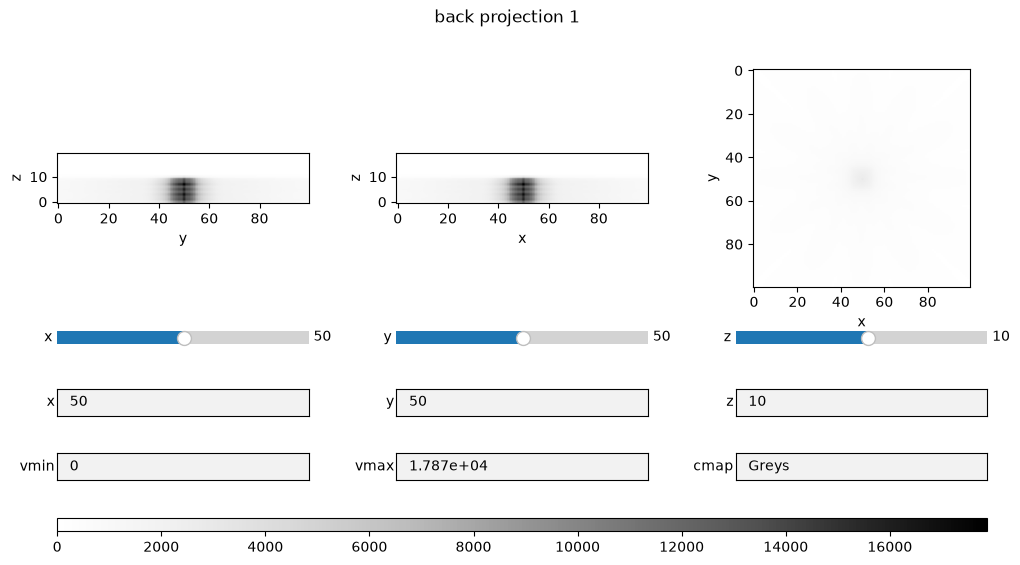

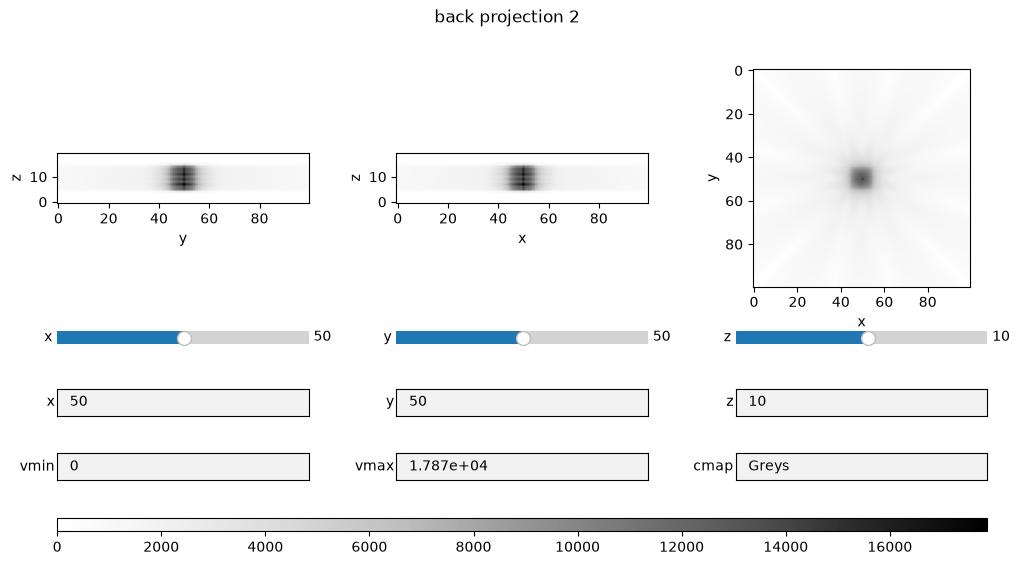

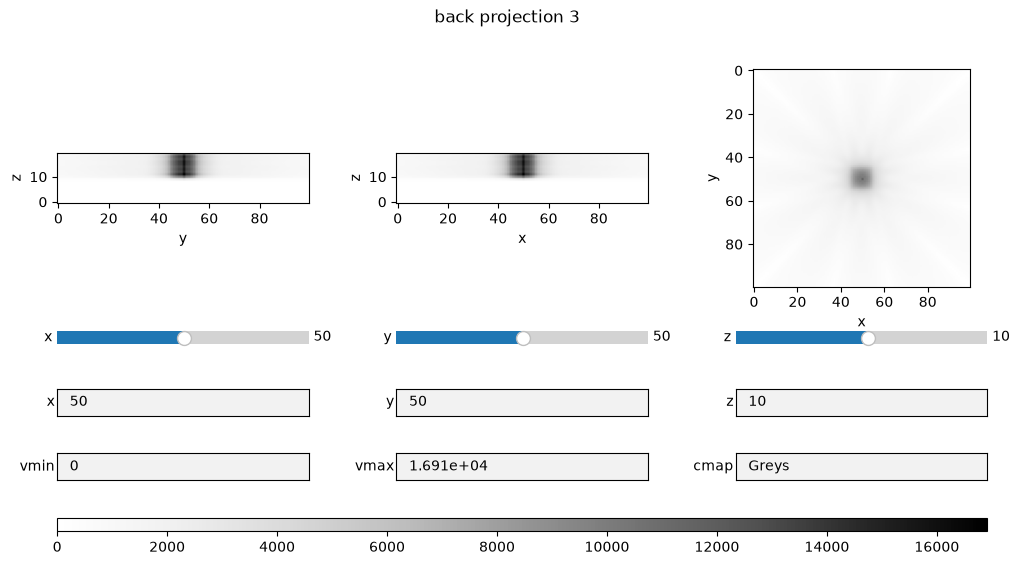

In [44]:
fig, _, widgets = show_vol_cuts(
    back[0], fig_title="back projection 1"
)
fig.savefig("back 1")
fig.show()

fig2, _, widgets2 = show_vol_cuts(
    back[1], fig_title="back projection 2"
)
fig2.savefig("back 2")
fig2.show()

fig3, _, widgets3 = show_vol_cuts(
    back[2], fig_title="back projection 3"
)
fig3.savefig("back 3")
fig3.show()

In [ ]:
mlem=[]
x_mlem = xp.ones((100, 100), device=dev, dtype=xp.float32)
sens_img = proj.adjoint(sens_sino)

for i in range(num_iter):
    exp = sens_sino * proj(x_mlem) + contam
    ratio = emis_sino / exp
    ratio_back = proj.adjoint(sens_sino * ratio)

    update_img = ratio_back / sens_img
    x_mlem *= update_img